# Proyek Analisis Data: [Input Nama Dataset]
- **Nama:** Kayla Arianto
- **Email:** kayla.arianto@gmail.com
- **ID Dicoding:** DS010B6X0869

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Konsentrasi PM2.5 per stasiun (prioritas intervensi kebijakan): stasiun pemantayan udara mana saja yang mencatat rata-rata konsentrasi PM2.5 tertinggi dan berapa selisih persentasenya dibanding stasiun terendah selama periode Maret 2013-Februari 2017, sehingga prioritas intervensi pengendalian polusi udara dapat diarahkan ke lokasi tersebut?
- **Pertanyaan 2:** Lonjakan PM2.5 dan PM10 per bulan dan jam (penjadwalan aktivitas kesehatan): Pada bulan dan jam berapa terjadi lonjakan rata-rata kadar PM2.5 dan PM10 tertinggi sepanjang tahun (2013-2017), serta berapa persentase kenaikannya dibanding jam terendah agar imbauan perlindungan diri dan pengaturan aktivitas luar ruang dapat dijadwalkan lebih tepat?

## Import Semua Packages/Library yang Digunakan

In [2]:
import glob
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

## Data Wrangling

### Gathering Data

#### Load df ...

In [6]:
import glob
from google.colab import drive

drive.mount("/content/drive")

file_paths = sorted(
    glob.glob(
        "/content/drive/MyDrive/PRSA_Data_20130301-20170228/**/PRSA_Data_*_20130301-20170228.csv",
        recursive=True,
    )
)

station_dfs = []
for path in file_paths:
  temp_df = pd.read_csv(path, delimiter=",")
  if "station" not in temp_df.columns:
    temp_df["station"] = os.path.basename(path).split("_")[2]
  station_dfs.append(temp_df)

if not station_dfs:
  raise FileNotFoundError(
      "File PRSA_Data_*_20130301-20170228.csv tidak ditemukan. Upload file ke"
      " Colab atau cek path folder."
  )

air_quality_df = pd.concat(station_dfs, axis=0, ignore_index=True)
air_quality_df.head()

Mounted at /content/drive


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

**Insight:** (Opsional)
- Google Drive berhasil terhubung dan data stasiun termuat ke satu tabel.
- Kolom waktu dan polutan utama sudah terbaca lengkap di tampilan 5 baris awal.

### Assessing Data

#### Identifying ... problem

In [7]:
# 1. Cek informasi kolom, jumlah non-null, dan tipe data
air_quality_df.info()

# 2. Cek jumlah missing value per kolom
print("\nMissing values per kolom:")
print(air_quality_df.isna().sum())

# 3. Cek jumlah data duplikat
print("\nJumlah duplikasi:", air_quality_df.duplicated().sum())

# 4. Cek ringkasan statistik kolom numerik (cek nilai min/max/outlier)
air_quality_df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420768 entries, 0 to 420767
Data columns (total 18 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   No       420768 non-null  int64  
 1   year     420768 non-null  int64  
 2   month    420768 non-null  int64  
 3   day      420768 non-null  int64  
 4   hour     420768 non-null  int64  
 5   PM2.5    412029 non-null  float64
 6   PM10     414319 non-null  float64
 7   SO2      411747 non-null  float64
 8   NO2      408652 non-null  float64
 9   CO       400067 non-null  float64
 10  O3       407491 non-null  float64
 11  TEMP     420370 non-null  float64
 12  PRES     420375 non-null  float64
 13  DEWP     420365 non-null  float64
 14  RAIN     420378 non-null  float64
 15  wd       418946 non-null  object 
 16  WSPM     420450 non-null  float64
 17  station  420768 non-null  object 
dtypes: float64(11), int64(5), object(2)
memory usage: 57.8+ MB

Missing values per kolom:
No             0
y

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,WSPM
count,420768.000000,420768.000000,420768.000000,420768.000000,420768.000000,412029.000000,414319.000000,411747.000000,408652.000000,400067.000000,407491.000000,420370.000000,420375.000000,420365.000000,420378.000000,420450.000000
mean,17532.500000,2014.662560,6.522930,15.729637,11.500000,79.793428,104.602618,15.830835,50.638586,1230.766454,57.372271,13.538976,1010.746982,2.490822,0.064476,1.729711
std,10122.116943,1.177198,3.448707,8.800102,6.922195,80.822391,91.772426,21.650603,35.127912,1160.182716,56.661607,11.436139,10.474055,13.793847,0.821004,1.246386
min,1.000000,2013.000000,1.000000,1.000000,0.000000,2.000000,2.000000,0.285600,1.026500,100.000000,0.214200,-19.900000,982.400000,-43.400000,0.000000,0.000000
25%,8766.750000,2014.000000,4.000000,8.000000,5.750000,20.000000,36.000000,3.000000,23.000000,500.000000,11.000000,3.100000,1002.300000,-8.900000,0.000000,0.900000
50%,17532.500000,2015.000000,7.000000,16.000000,11.500000,55.000000,82.000000,7.000000,43.000000,900.000000,45.000000,14.500000,1010.400000,3.100000,0.000000,1.400000
75%,26298.250000,2016.000000,10.000000,23.000000,17.250000,111.000000,145.000000,20.000000,71.000000,1500.000000,82.000000,23.300000,1019.000000,15.100000,0.000000,2.200000
max,35064.000000,2017.000000,12.000000,31.000000,23.000000,999.000000,999.000000,500.000000,290.000000,10000.000000,1071.000000,41.600000,1042.800000,29.100000,72.500000,13.200000


**Steps to Take:**
- Membentuk kolom datetime: Menggabungkan kolom year, month, day, dan hour menjadi tipe data datetime untuk memudahkan pengurutan waktu dan filter tanggal.
- Memeriksa dan menangani nilai tidak wajar.
- Menangani missing value pada PM2.5 dan PM10.

**Insight:** (Opsional)
- Tidak ada baris duplikat dan kolom identitas/waktu lengkap
- Terdapat missing value signifikan pada kolom polutan utama dan variabel pendukung
- Tipe data sudah sesuai & waktu masih terpisah

### Cleaning Data

#### Fixing ... problem

In [8]:
clean_aq_df = air_quality_df.copy()

# 1. Menghapus data duplikat (jika ada)
clean_aq_df.drop_duplicates(inplace=True)
print("Jumlah duplikasi setelah dibersihkan:", clean_aq_df.duplicated().sum())

# 2. Membuat kolom datetime dari year, month, day, hour
clean_aq_df["datetime"] = pd.to_datetime(
    clean_aq_df[["year", "month", "day", "hour"]]
)

# 3. Menangani nilai tidak wajar (nilai polutan negatif dijadikan NaN)
for col in ["PM2.5", "PM10"]:
  if col in clean_aq_df.columns:
    clean_aq_df.loc[clean_aq_df[col] < 0, col] = np.nan

# 4. Menangani missing value pada kolom utama (PM2.5 dan PM10)
clean_aq_df = clean_aq_df.dropna(subset=["PM2.5", "PM10"])

print("\nMissing values PM2.5 & PM10 setelah cleaning:")
print(clean_aq_df[["PM2.5", "PM10"]].isna().sum())
clean_aq_df.info()

Jumlah duplikasi setelah dibersihkan: 0

Missing values PM2.5 & PM10 setelah cleaning:
PM2.5    0
PM10     0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 411813 entries, 0 to 420767
Data columns (total 19 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   No        411813 non-null  int64         
 1   year      411813 non-null  int64         
 2   month     411813 non-null  int64         
 3   day       411813 non-null  int64         
 4   hour      411813 non-null  int64         
 5   PM2.5     411813 non-null  float64       
 6   PM10      411813 non-null  float64       
 7   SO2       408124 non-null  float64       
 8   NO2       405076 non-null  float64       
 9   CO        396667 non-null  float64       
 10  O3        403670 non-null  float64       
 11  TEMP      411417 non-null  float64       
 12  PRES      411422 non-null  float64       
 13  DEWP      411412 non-null  float64       
 14  RAIN      41142

**Insight:** (Opsional)
- xxx
- xxx

## Exploratory Data Analysis (EDA)

### Explore ...

In [9]:
# 1. Agregasi rata-rata dan statistik PM2.5 per stasiun
station_pm25 = (
    clean_aq_df.groupby(by="station", observed=False)["PM2.5"]
    .agg(mean_pm25="mean", median_pm25="median", count="count")
    .sort_values(by="mean_pm25", ascending=False)
    .reset_index()
)

highest_station = station_pm25.iloc[0]
lowest_station = station_pm25.iloc[-1]
pct_diff_station = (
    (highest_station["mean_pm25"] - lowest_station["mean_pm25"])
    / lowest_station["mean_pm25"]
) * 100

print(station_pm25)
print(
    f"\nTertinggi: {highest_station['station']}"
    f" ({highest_station['mean_pm25']:.2f} µg/m³)"
)
print(
    f"Terendah: {lowest_station['station']}"
    f" ({lowest_station['mean_pm25']:.2f} µg/m³)"
)
print(f"Selisih persentase (tertinggi vs terendah): {pct_diff_station:.2f}%")

# 2. Agregasi bulanan (1 - 12) dan per jam (0 - 23) untuk PM2.5 dan PM10
monthly_pollutants = (
    clean_aq_df.groupby(by="month", observed=False)[["PM2.5", "PM10"]]
    .mean()
    .reset_index()
)

hourly_pollutants = (
    clean_aq_df.groupby(by="hour", observed=False)[["PM2.5", "PM10"]]
    .mean()
    .reset_index()
)

print("\nRata-rata bulanan:")
print(monthly_pollutants)

print("\nPuncak & terendah per jam:")
for col in ["PM2.5", "PM10"]:
  peak_row = hourly_pollutants.loc[hourly_pollutants[col].idxmax()]
  low_row = hourly_pollutants.loc[hourly_pollutants[col].idxmin()]
  pct_increase_hour = ((peak_row[col] - low_row[col]) / low_row[col]) * 100
  print(
      f"{col} -> Jam puncak: {int(peak_row['hour']):02d}:00"
      f" ({peak_row[col]:.2f}), Jam terendah: {int(low_row['hour']):02d}:00"
      f" ({low_row[col]:.2f}), Kenaikan: {pct_increase_hour:.2f}%"
  )

          station  mean_pm25  median_pm25  count
0          Dongsi  86.159385         61.0  34295
1   Wanshouxigong  84.926712         60.0  34351
2    Nongzhanguan  84.817059         59.0  34421
3         Gucheng  83.829657         60.0  34400
4          Wanliu  83.364412         59.0  34661
5        Guanyuan  82.910468         59.0  34437
6    Aotizhongxin  82.747386         58.0  34130
7         Tiantan  82.098537         59.0  34371
8          Shunyi  79.439865         55.0  34128
9       Changping  71.063053         46.0  34276
10        Huairou  69.555859         46.0  34086
11       Dingling  65.964880         41.0  34257

Tertinggi: Dongsi (86.16 µg/m³)
Terendah: Dingling (65.96 µg/m³)
Selisih persentase (tertinggi vs terendah): 30.61%

Rata-rata bulanan:
    month       PM2.5        PM10
0       1   93.579017  112.949984
1       2   87.299749  102.709272
2       3   94.666808  136.122668
3       4   72.651583  116.721102
4       5   62.955499  107.082537
5       6   69.107388 

**Insight:** (Opsional)
- xxx
- xxx

## Visualization & Explanatory Analysis

### Pertanyaan 1:

/tmp/ipykernel_659/3259052531.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


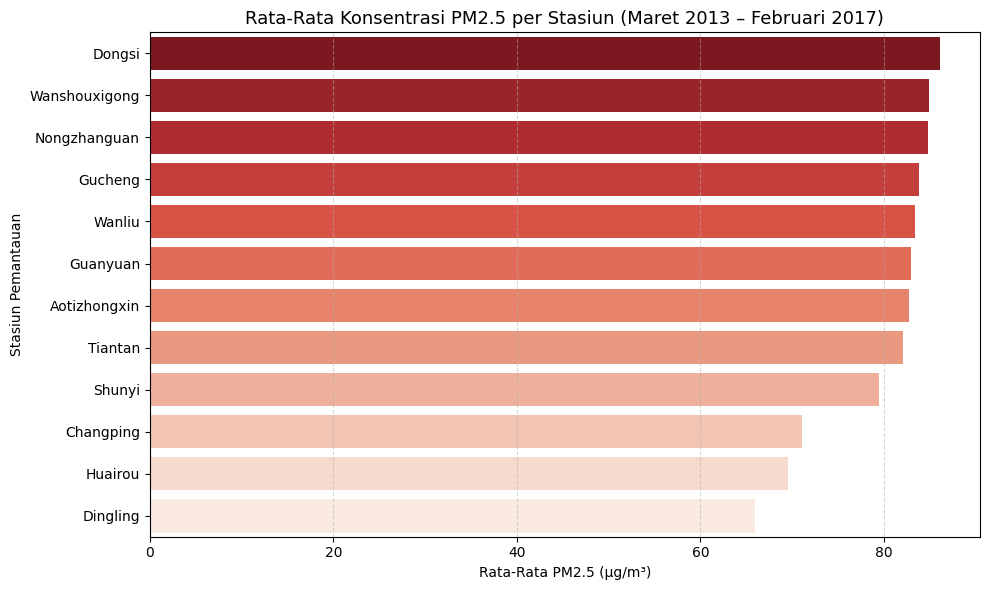

In [10]:
plt.figure(figsize=(10, 6))
sns.barplot(
    data=station_pm25,
    x="mean_pm25",
    y="station",
    palette="Reds_r",
)
plt.title(
    "Rata-Rata Konsentrasi PM2.5 per Stasiun (Maret 2013 – Februari 2017)",
    fontsize=13,
)
plt.xlabel("Rata-Rata PM2.5 (µg/m³)")
plt.ylabel("Stasiun Pemantauan")
plt.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### Pertanyaan 2:

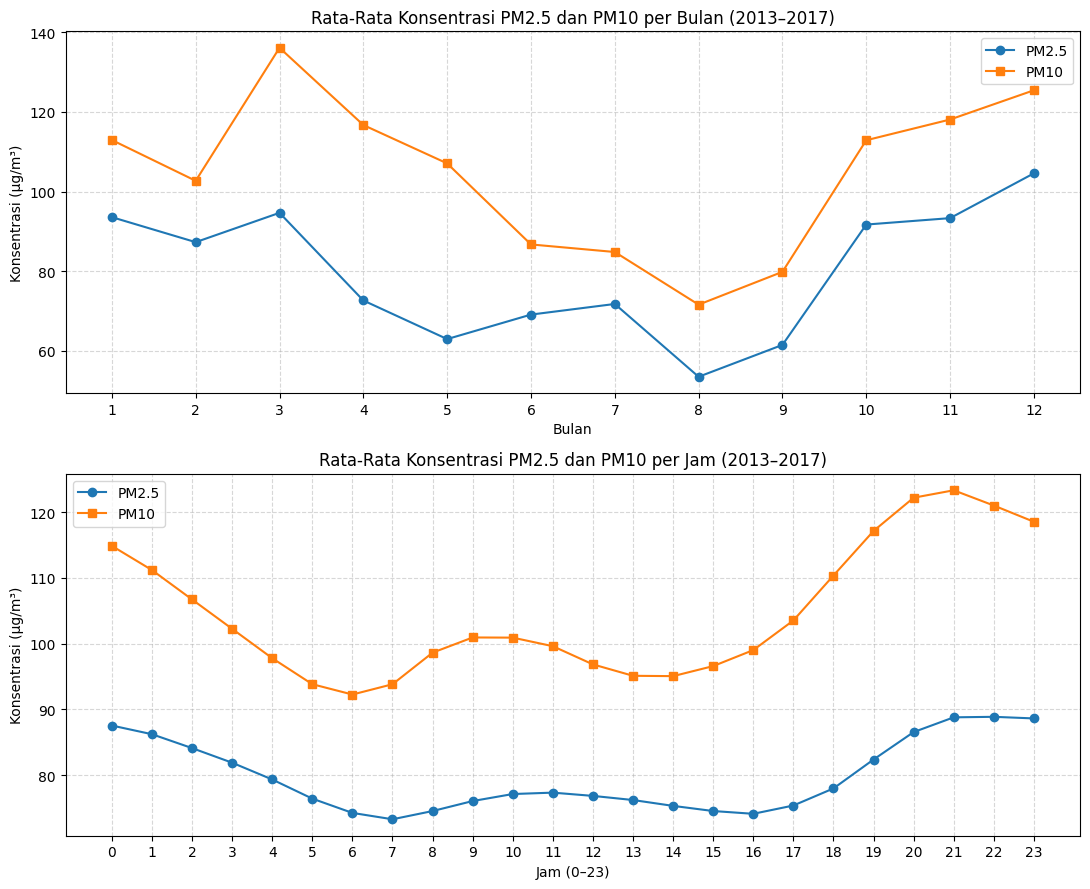

In [11]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(11, 9))

# Grafik atas: Tren bulanan
axes[0].plot(
    monthly_pollutants["month"],
    monthly_pollutants["PM2.5"],
    marker="o",
    label="PM2.5",
)
axes[0].plot(
    monthly_pollutants["month"],
    monthly_pollutants["PM10"],
    marker="s",
    label="PM10",
)
axes[0].set_title("Rata-Rata Konsentrasi PM2.5 dan PM10 per Bulan (2013–2017)")
axes[0].set_xlabel("Bulan")
axes[0].set_ylabel("Konsentrasi (µg/m³)")
axes[0].set_xticks(range(1, 13))
axes[0].legend()
axes[0].grid(True, linestyle="--", alpha=0.5)

# Grafik bawah: Tren per jam
axes[1].plot(
    hourly_pollutants["hour"],
    hourly_pollutants["PM2.5"],
    marker="o",
    label="PM2.5",
)
axes[1].plot(
    hourly_pollutants["hour"],
    hourly_pollutants["PM10"],
    marker="s",
    label="PM10",
)
axes[1].set_title("Rata-Rata Konsentrasi PM2.5 dan PM10 per Jam (2013–2017)")
axes[1].set_xlabel("Jam (0–23)")
axes[1].set_ylabel("Konsentrasi (µg/m³)")
axes[1].set_xticks(range(0, 24))
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

**Insight:** (Opsional)
- Dongsi menempati peringkat tertinggi dan Dingling terendah: Rata-rata konsentrasi PM2.5 tertinggi tercatat di stasiun Dongsi (sekitar di atas 85 µg/m³), diikuti oleh Wanshouxigong dan Nongzhanguan di posisi tiga besar. Sebaliknya, Dingling berada di posisi paling bawah (sekitar 65–66 µg/m³), diikuti oleh Huairou dan Changping.
- Terdapat rentang perbedaan yang jelas antar-stasiun: Seluruh stasiun berada pada kisaran rata-rata sekitar 65 hingga lebih dari 85 µg/m³, dengan kelompok stasiun perkotaan/padat di bagian atas dan stasiun yang lebih pinggiran/utara seperti Dingling dan Huairou di bagian bawah. Perbedaan rata-rata ini menunjukkan bahwa prioritas pengendalian polusi udara tidak merata di tiap titik pemantauan.
- Pola bulanan: PM10 memuncak di bulan 3 (~136 µg/m³) dan PM2.5 memuncak di bulan 12 (~105 µg/m³), sementara keduanya terendah di bulan 8 dengan PM10 selalu lebih tinggi dari PM2.5
- Pola per jam: Kedua polutan paling rendah sekitar jam 06:00–07:00 dan mencapai puncak pada malam hari sekitar jam 21:00 (PM2.5 ~89 µg/m³ dan PM10 >123 µg/m³).

## Analisis Lanjutan (Opsional)

In [12]:
clean_aq_df.to_csv("clean_air_quality.csv", index=False)

**Insight:** (Opsional)
- xxx
- xxx

## Conclusion & Recommendation

- **Conclusion pertanyaan 1:** Pada periode Maret 2013–Februari 2017, Dongsi mencatat rata-rata konsentrasi PM2.5 tertinggi di antara seluruh stasiun (sekitar >85 µg/m³), diikuti oleh Wanshouxigong dan Nongzhanguan. Sebaliknya, Dingling mencatat rata-rata PM2.5 terendah (sekitar ~65–66 µg/m³), sehingga terdapat selisih yang cukup lebar antara stasiun tertinggi dan terendah untuk dijadikan dasar prioritas intervensi kualitas udara
- **Conclusion pertanyaan 2:** Pada pola bulanan, rata-rata PM2.5 memuncak di bulan 12 (sekitar ~105 µg/m³) sementara PM10 melonjak paling tinggi di bulan 3 (sekitar >135 µg/m³), dan keduanya cenderung paling rendah di bulan 8. Pada pola per jam, konsentrasi PM2.5 dan PM10 mencapai puncaknya pada rentang malam hari sekitar jam 21:00 (PM2.5 mendekati ~89 µg/m³ dan PM10 di atas ~123 µg/m³), sedangkan titik terendahnya berada di pagi hari sekitar jam 06:00–07:00.
- Kesenjangan antar-stasiun serta variasi musiman dan jam puncak menunjukkan bahwa kualitas udara dipengaruhi oleh lokasi pemantauan sekaligus siklus waktu tertentu, yang dapat dipantau secara interaktif melalui filter stasiun dan rentang tanggal pada dashboard Streamlit.

**Rekomendasi Action Item:**
- Prioritaskan intervensi dan pengawasan di stasiun dengan PM2.5 tertinggi: Fokuskan kebijakan pengendalian emisi, inspeksi sumber pencemar, serta pemantauan udara pada stasiun teratas seperti Dongsi, Wanshouxigong, dan Nongzhanguan, sambil memanfaatkan dashboard Streamlit untuk membandingkan tren antar-stasiun pada rentang waktu tertentu.
- Sesuaikan imbauan kesehatan dan jadwal aktivitas luar ruang dengan bulan serta jam puncak: Tingkatkan peringatan dini, penggunaan masker, dan penyesuaian aktivitas luar ruang sensitif pada bulan dengan lonjakan tinggi (seperti bulan 3 untuk PM10 dan bulan 10–12 untuk PM2.5 serta PM10), khususnya pada jam malam puncak (sekitar pukul 20:00–22:00) dibandingkan jam pagi yang relatif lebih rendah.